In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ipynb.fs.full.preprocessing as pp


,x,cx_mm,y,cy_mm
0,-0.40,1.306426,0.0,0.009960
1,-0.30,1.083378,0.0,-0.009960
2,-0.20,0.764737,0.0,0.000000
3,-0.10,0.371747,0.0,0.019920
4,0.00,-0.000000,0.0,0.000000
5,0.10,-0.318640,0.0,0.000000
6,0.20,-0.711630,0.0,0.029880
7,0.30,-1.136484,0.0,0.079681
8,0.40,-1.476367,0.0,0.099602
9,-0.40,1.232076,0.0,0.119522


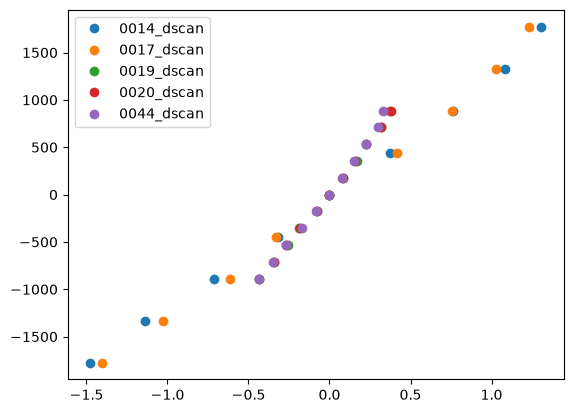

In [ ]:
x_px = 214.91 - 196.08 #0.1mm
y_px = 45.12 - 25.04 #0.1mm
x_conversion = 0.1/x_px #px to mm conversion 
y_conversion = 0.1/y_px #px to mm conversion 
data = pp.combine_the_data([("0014_dscan", True),("0017_dscan", True),("0019_dscan", False),("0020_dscan", False),("0044_dscan", True)], x_conversion=x_conversion, y_conversion=y_conversion)
display(data[["x", "cx_mm", "y", "cy_mm"]])

For this test example - I am going to estimate the mm to pixels - this estimation has been done separately to the scan so is invalid and it only for testing and logic purposes. 

There is a factor of ~2 different here in the x to cx_mm conversion - probably due to my conversion - the microscope may have been further away when I did the calibration. 

This is just a test to get used to the NN side of things so I will leave it for now.

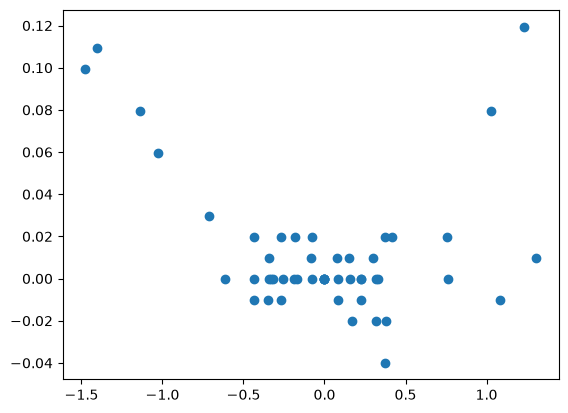

In [3]:
plt.scatter(data["cx_mm"], data["cy_mm"])

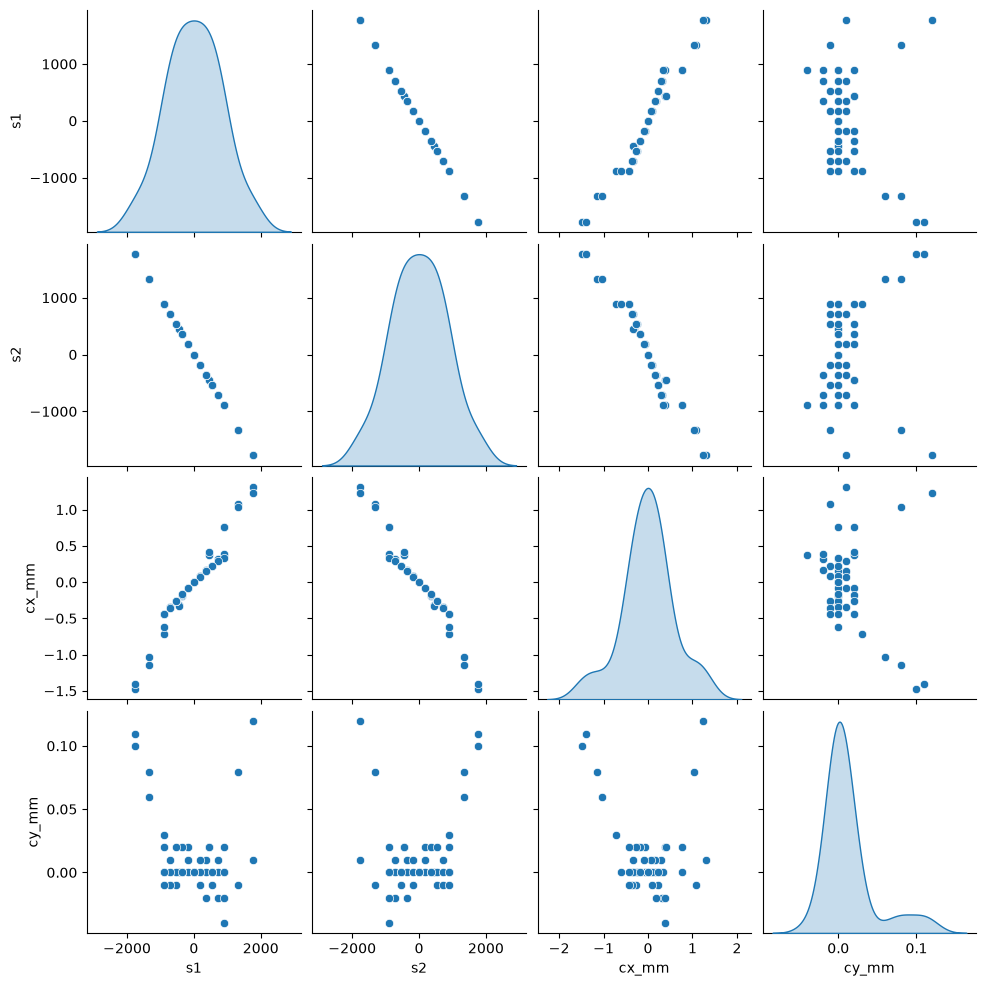

In [4]:
import seaborn as sns
sns.pairplot(data[[ "s1", "s2", "cx_mm", "cy_mm"]], diag_kind='kde')

<h1> Tensor Flow Basic Regression Tutorial but with my data </h1>

In [5]:
#need multiple inputs - s0,s1,s1 and multiple outputs cx_mm, cy_mm
#For now just doing one output - s1 and two inputs - cx_mm, cy_mm (initially just cx_mm)

inputs = data[["cx_mm", "cy_mm"]]
outputs = data[["s0", "s1", "s2"]]
# dataset = data[["cx_mm", "cy_mm", "s0", "s1", "s2"]]
dataset = data[["cx_mm", "cy_mm", "s1"]]
dataset = dataset.reset_index(drop=True) #reset indexes as multiple datapoints combined
# x_train, x_test, y_train, y_test = train_test_split(inputs, outputs, test_size=0.2)
train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)
# print(train_dataset)
print(test_dataset)

       cx_mm     cy_mm    s1
0   1.306426  0.009960  1774
3   0.371747  0.019920   443
9   1.232076  0.119522  1774
19  0.318640 -0.019920   709
21  0.169942 -0.019920   355
36 -0.180563  0.019920  -355
39 -0.435475  0.019920  -887
44  0.074349  0.009960   177
47 -0.169942  0.000000  -355
49 -0.350505 -0.009960  -709


In [6]:
train_dataset.tail()

,cx_mm,cy_mm,s1
12,0.414233,0.01992,443
38,-0.339883,0.00996,-709
24,-0.074349,0.00000,-177
6,-0.711630,0.02988,-887
23,0.000000,0.00000,0


The tutorial is only to predict one output. As s0=0 and s1=-s2,just predict s1 for now 

In [7]:
train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('s1')
test_labels = test_features.pop('s1')

print(test_features)
print(test_labels)

       cx_mm     cy_mm
0   1.306426  0.009960
3   0.371747  0.019920
9   1.232076  0.119522
19  0.318640 -0.019920
21  0.169942 -0.019920
36 -0.180563  0.019920
39 -0.435475  0.019920
44  0.074349  0.009960
47 -0.169942  0.000000
49 -0.350505 -0.009960
0     1774
3      443
9     1774
19     709
21     355
36    -355
39    -887
44     177
47    -355
49    -709
Name: s1, dtype: int64


In [8]:
train_dataset.describe().transpose()[['mean', 'std']]


,mean,std
cx_mm,-0.070464,0.561606
cy_mm,0.011418,0.030905
s1,-71.365854,791.741617


In [9]:
#normalise features - maybe don't need as all inputs have the same range
import tensorflow as tf
normalizer = tf.keras.layers.Normalization(axis=-1)
normalizer.adapt(np.array(train_features))
print(normalizer.mean.numpy())


I0000 00:00:1790866361.371448   17759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790866361.511642   17759 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790866362.465997   17759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[[-0.07046358  0.01141774]]


W0000 00:00:1790866363.024995   17759 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [10]:
first = np.array(train_features[:1])
print(train_features[:1])
with np.printoptions(precision=2, suppress=True):
  print('First example:', first)
  print()
  print('Normalized:', normalizer(first).numpy())


       cx_mm    cy_mm
29  0.382369 -0.01992
First example: [[ 0.38 -0.02]]

Normalized: [[ 0.82 -1.03]]


<h3>Linear Regression

In [11]:
from tensorflow.keras import layers

cx = np.array(train_features['cx_mm'])

cx_normalizer = layers.Normalization(input_shape=[1,], axis=None)
cx_normalizer.adapt(cx)


/scratch/dvu71330/grad_project_3/TensorFlow/.venv/lib64/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
cx_model = tf.keras.Sequential([
    cx_normalizer,
    layers.Dense(units=1)
])

cx_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 3 (16.00 B)

In [13]:
cx_model.predict(cx[:10])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


array([[ 0.8456613 ],
       [ 1.539897  ],
       [ 2.0556147 ],
       [ 0.2902727 ],
       [ 1.5597322 ],
       [-0.6816572 ],
       [ 0.1315903 ],
       [ 0.42911988],
       [-0.344457  ],
       [ 0.1315903 ]], dtype=float32)

In [14]:
cx_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')


In [15]:
history = cx_model.fit(
    train_features['cx_mm'],
    train_labels,
    epochs=100,
    # Suppress logging.
    verbose=0,
    # Calculate validation results on 20% of the training data.
    validation_split = 0.2)

In [16]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,val_loss,epoch
95,599.690063,738.938477,95
96,599.622437,738.843872,96
97,599.553772,738.749756,97
98,599.487610,738.657104,98
99,599.419983,738.565430,99


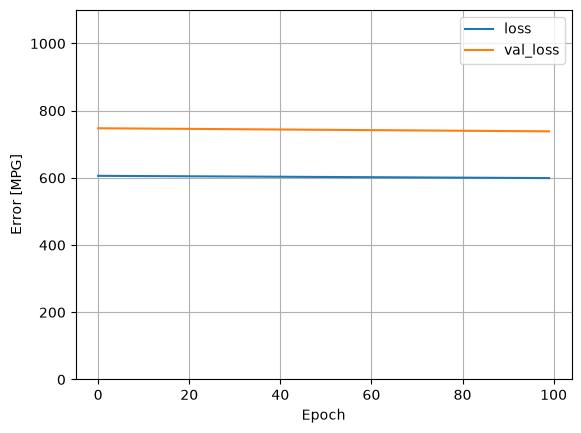

In [17]:
def plot_loss(history):
  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
  plt.ylim([0, 1100])
  plt.xlabel('Epoch')
  plt.ylabel('Error [MPG]')
  plt.legend()
  plt.grid(True)
plot_loss(history)


In [18]:
test_results = {}

test_results['cx_model'] = cx_model.evaluate(
    test_features['cx_mm'],
    test_labels, verbose=0)


In [19]:
x = tf.linspace(-1.5, 1.5, 251)
y = cx_model.predict(x)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


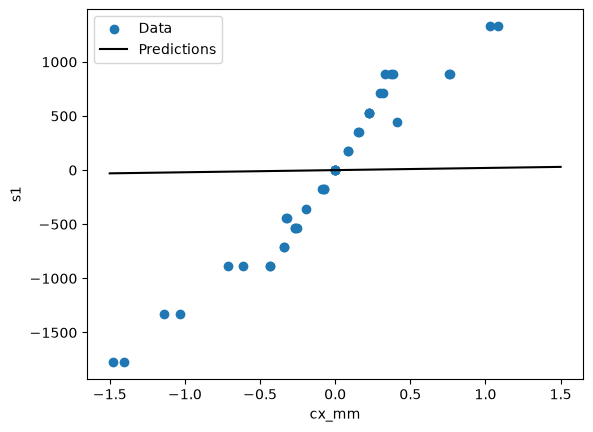

In [20]:
def plot_cx(x, y):
  plt.scatter(train_features['cx_mm'], train_labels, label='Data')
  plt.plot(x, y, color='k', label='Predictions')
  plt.xlabel('cx_mm')
  plt.ylabel('s1')
  plt.legend()
plot_cx(x, y)


<h4>Multiple Inputs

In [21]:
#multiple inputs cx_mm and cy_mm
linear_model = tf.keras.Sequential([
    normalizer,
    layers.Dense(units=1)
])
linear_model.predict(train_features[:10])
linear_model.layers[1].kernel
linear_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


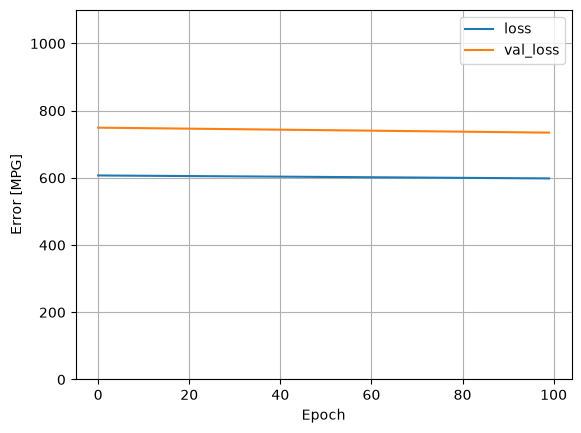

In [22]:
history = linear_model.fit(
    train_features,
    train_labels,
    epochs=100,
    # Suppress logging.
    verbose=0,
    # Calculate validation results on 20% of the training data.
    validation_split = 0.2)
plot_loss(history)

In [23]:
test_results['linear_model'] = linear_model.evaluate(
    test_features, test_labels, verbose=0)


<h3>DNN

In [24]:
def build_and_compile_model(norm):
  model = tf.keras.Sequential([
      norm,
      layers.Dense(64, activation='relu'),
      layers.Dense(64, activation='relu'),
      layers.Dense(1)
  ])

  model.compile(loss='mean_absolute_error',
                optimizer=tf.keras.optimizers.Adam(0.001))
  return model

In [25]:
dnn_cx_model = build_and_compile_model(cx_normalizer)
dnn_cx_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,356 (17.02 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 3 (16.00 B)

In [26]:
history = dnn_cx_model.fit(
    train_features['cx_mm'],
    train_labels,
    validation_split=0.2,
    verbose=0, epochs=100)

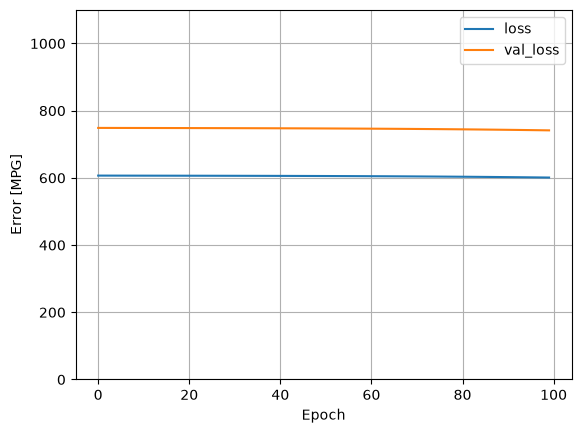

In [27]:
plot_loss(history)


1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/stepWARNING:tensorflow:5 out of the last 17 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7faab01ab060> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


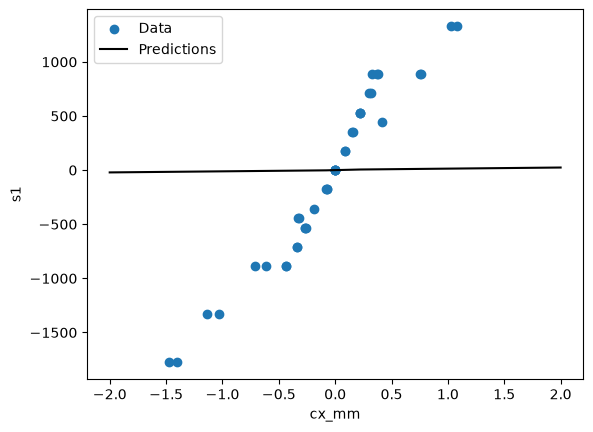

In [28]:
x = tf.linspace(-2, 2, 251)
y = dnn_cx_model.predict(x)
plot_cx(x, y)


In [29]:
test_results['dnn_cx_model'] = dnn_cx_model.evaluate(
    test_features['cx_mm'], test_labels,
    verbose=0)



DNN Multiple inputs

In [30]:
dnn_model = build_and_compile_model(normalizer)
dnn_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (10, 2)                │             5 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 5 (24.00 B)

In [31]:
%%time
history = dnn_model.fit(
    train_features,
    train_labels,
    validation_split=0.2,
    verbose=0, epochs=100)


CPU times: user 4.52 s, sys: 686 ms, total: 5.21 s
Wall time: 4.55 s


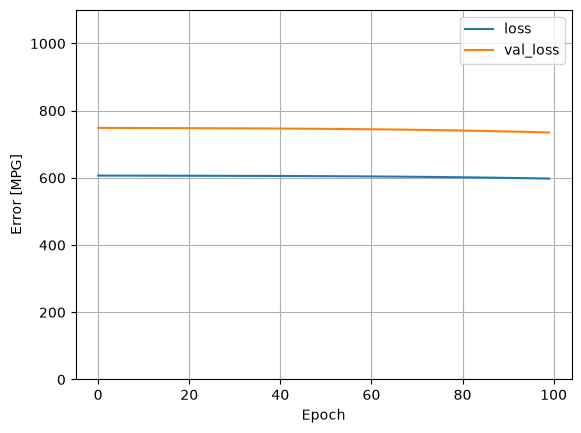

In [32]:
plot_loss(history)



In [33]:
test_results['dnn_model'] = dnn_model.evaluate(test_features, test_labels, verbose=0)


In [34]:
print(test_results)
pd.DataFrame(test_results, index=['Mean absolute error [MPG]']).T


{'cx_model': 744.6318359375, 'linear_model': 748.1920776367188, 'dnn_cx_model': 746.402587890625, 'dnn_model': 746.6173095703125}


,Mean absolute error [MPG]
cx_model,744.631836
linear_model,748.192078
dnn_cx_model,746.402588
dnn_model,746.617310
